<a href="https://colab.research.google.com/github/vishwakumar1311/Bigram/blob/main/Bigram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# load names.txt from this repo (downloaded from GitHub if not found locally)
import os
import random
import urllib.request

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

NAMES_URL = "https://raw.githubusercontent.com/vishwakumar1311/Bigram/main/names.txt"
if not os.path.exists("names.txt"):
    urllib.request.urlretrieve(NAMES_URL, "names.txt")

words = open("names.txt").read().splitlines()
print(len(words), "names:", words[:8])

32033 names: ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [2]:
# vocabulary ('.' marks start/end of a name) and 80/10/10 train/dev/test split
chars = sorted(set("".join(words)))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(stoi)
print(vocab_size, "tokens:", "".join(itos[i] for i in range(vocab_size)))

random.seed(42)
random.shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
train_words, dev_words, test_words = words[:n1], words[n1:n2], words[n2:]
print(len(train_words), len(dev_words), len(test_words))

27 tokens: .abcdefghijklmnopqrstuvwxyz
25626 3203 3204


In [3]:
# bigram baseline: next-character counts with +1 smoothing, scored by NLL
N = torch.zeros((vocab_size, vocab_size), dtype=torch.int32)
for w in train_words:
    seq = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(seq, seq[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

P = (N + 1).float()
P = P / P.sum(1, keepdim=True)

def bigram_nll(ws):
    log_likelihood, n = 0.0, 0
    for w in ws:
        seq = ["."] + list(w) + ["."]
        for ch1, ch2 in zip(seq, seq[1:]):
            log_likelihood += torch.log(P[stoi[ch1], stoi[ch2]])
            n += 1
    return -log_likelihood / n

print(f"bigram  dev NLL: {bigram_nll(dev_words):.4f}   test NLL: {bigram_nll(test_words):.4f}")

bigram  dev NLL: 2.4533   test NLL: 2.4584


In [4]:
# sample names from the bigram model
g = torch.Generator().manual_seed(2147483647)
for _ in range(10):
    out, ix = [], 0
    while True:
        ix = torch.multinomial(P[ix], num_samples=1, generator=g).item()
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

dexze
momakurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda


In [5]:
# MLP language model: build (3-character context -> next character) examples
block_size = 3

def build_dataset(ws):
    X, Y = [], []
    for w in ws:
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    return torch.tensor(X), torch.tensor(Y)

Xtr, Ytr = build_dataset(train_words)
Xdev, Ydev = build_dataset(dev_words)
Xte, Yte = build_dataset(test_words)
print(Xtr.shape, Xdev.shape, Xte.shape)

# what the model sees for the first name
for x, y in list(zip(Xtr, Ytr))[:6]:
    print("".join(itos[i.item()] for i in x), "--->", itos[y.item()])

torch.Size([182625, 3]) torch.Size([22655, 3]) torch.Size([22866, 3])


... ---> y
..y ---> u
.yu ---> h
yuh ---> e
uhe ---> n
hen ---> g


In [6]:
# MLP parameters and forward pass
n_embd, n_hidden = 10, 300

def init_params():
    g = torch.Generator().manual_seed(2147483647)
    C = torch.randn((vocab_size, n_embd), generator=g)
    W1 = torch.randn((block_size * n_embd, n_hidden), generator=g) * (5 / 3) / (block_size * n_embd) ** 0.5
    b1 = torch.zeros(n_hidden)
    W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
    b2 = torch.zeros(vocab_size)
    params = [C, W1, b1, W2, b2]
    for p in params:
        p.requires_grad = True
    return params

def forward(params, X):
    C, W1, b1, W2, b2 = params
    emb = C[X]
    h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
    return h @ W2 + b2

@torch.no_grad()
def split_loss(params, X, Y):
    return F.cross_entropy(forward(params, X), Y).item()

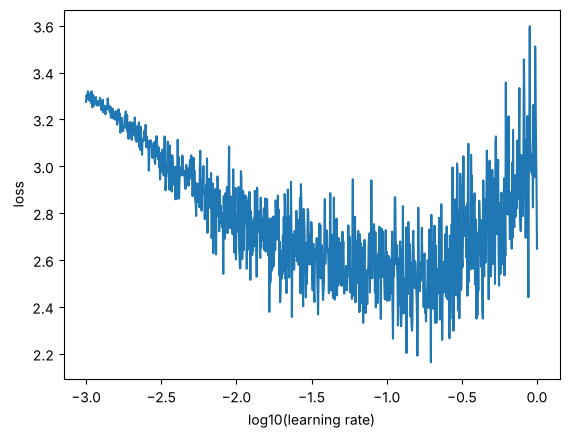

In [7]:
# learning-rate sweep from 0.001 to 1
params = init_params()
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre
lri, lossi = [], []
g = torch.Generator().manual_seed(0)
for i in range(1000):
    ix = torch.randint(0, Xtr.shape[0], (64,), generator=g)
    loss = F.cross_entropy(forward(params, Xtr[ix]), Ytr[ix])
    for p in params:
        p.grad = None
    loss.backward()
    for p in params:
        p.data -= lrs[i] * p.grad
    lri.append(lre[i].item())
    lossi.append(loss.item())

plt.plot(lri, lossi)
plt.xlabel("log10(learning rate)")
plt.ylabel("loss")
plt.show()

step      0  batch loss 3.3016


step  10000  batch loss 2.1267


step  20000  batch loss 2.3014


step  30000  batch loss 2.2467


step  40000  batch loss 2.0690


step  50000  batch loss 2.1271


step  60000  batch loss 2.2923


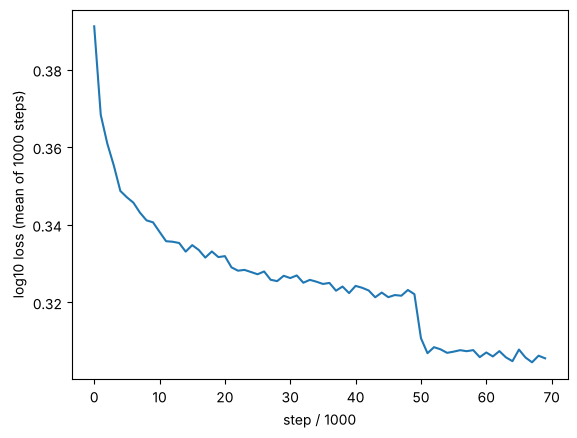

In [8]:
# train for 70,000 steps (lr 0.1, then 0.01 after step 50,000)
params = init_params()
g = torch.Generator().manual_seed(1)
steps, batch_size = 70_000, 64
lossi = []

for i in range(steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    loss = F.cross_entropy(forward(params, Xtr[ix]), Ytr[ix])
    for p in params:
        p.grad = None
    loss.backward()
    lr = 0.1 if i < 50_000 else 0.01
    for p in params:
        p.data -= lr * p.grad
    lossi.append(loss.log10().item())
    if i % 10_000 == 0:
        print(f"step {i:6d}  batch loss {loss.item():.4f}")

plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
plt.xlabel("step / 1000")
plt.ylabel("log10 loss (mean of 1000 steps)")
plt.show()

In [9]:
# train/dev/test loss, compared with the bigram baseline
print(f"MLP     train loss: {split_loss(params, Xtr, Ytr):.4f}")
print(f"MLP     dev   loss: {split_loss(params, Xdev, Ydev):.4f}")
print(f"MLP     test  loss: {split_loss(params, Xte, Yte):.4f}")
print(f"bigram  test  NLL : {bigram_nll(test_words):.4f}")

MLP     train loss: 2.0262
MLP     dev   loss: 2.0943
MLP     test  loss: 2.0939


bigram  test  NLL : 2.4584


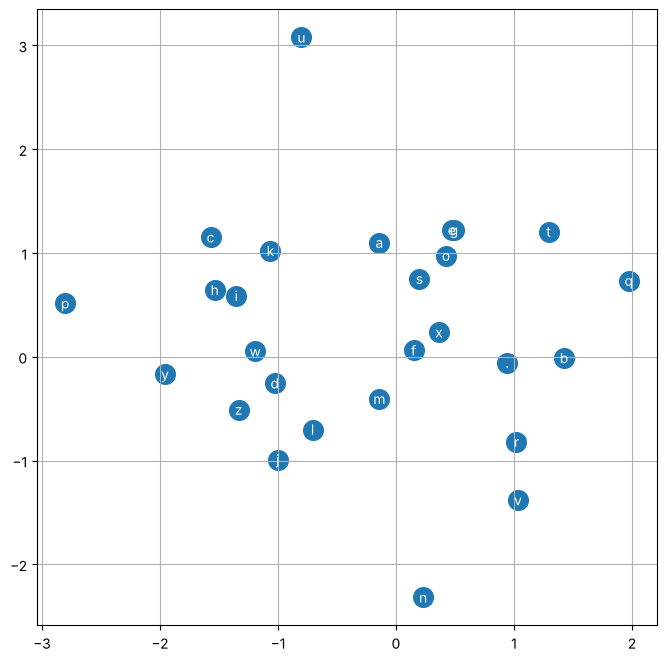

In [10]:
# plot the learned character embeddings (first 2 of 10 dimensions)
C = params[0]
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].detach(), C[:, 1].detach(), s=200)
for i in range(vocab_size):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha="center", va="center", color="white")
plt.grid(True)
plt.show()

In [11]:
# sample names from the MLP
g = torch.Generator().manual_seed(2147483647 + 10)
for _ in range(20):
    out, context = [], [0] * block_size
    while True:
        with torch.no_grad():
            logits = forward(params, torch.tensor([context]))
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

carmah
amelle
khy
mili
taty
skanden
jazonte
deliah
jareei
nellara
chaiir
kaleigh
ham
pole
quinthoroine
liven
corterri
jaristin
jenni
sabee
